In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

df = pd.read_csv("../../course_assignments/homework9/noisy_curvefit_data.csv")

print("Shape:", df.shape)
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
print("\nFirst 5 rows:")
print(df.head())
print("\nLast 5 rows:")
print(df.tail())
print("\nColumn names:", df.columns.tolist())


Shape: (100, 6)
Rows: 100, Columns: 6

First 5 rows:
          x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
0 -1.000000  11.624419   8.296963  12.201067   7.811725   3.155566
1 -0.929293  10.377466   9.674440  12.198084   8.275006   7.518855
2 -0.858586  10.585100   9.251983  13.186565  12.926586   9.963630
3 -0.787879  10.913928   7.786344  12.552304  11.832379   9.625801
4 -0.717172   8.640287   8.551869   4.741432   8.790834   6.624113

Last 5 rows:
           x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
95  5.717172  -1.411918   0.822231  -2.027132  -1.825106   2.746147
96  5.787879   0.344879  -1.718956   2.747559  -6.803779  -5.137472
97  5.858586   0.307133   0.353528   0.967976   5.461567  -0.905616
98  5.929293   0.048657   0.159961   2.482130  -0.414616  -4.334548
99  6.000000  -0.193438  -2.244792   1.930035   4.992414  -6.872850

Column names: ['x', 'y_noise_1', 'y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5']


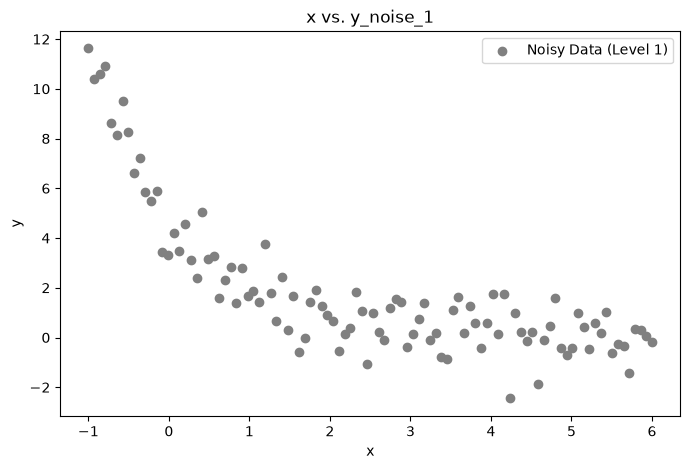

In [10]:
plt.figure(figsize=(8, 5))
plt.scatter(df["x"], df["y_noise_1"], color="gray", label="Noisy Data (Level 1)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("x vs. y_noise_1")
plt.legend()
plt.show()

Fit: y = 4.71 * e^(-0.92 * x)


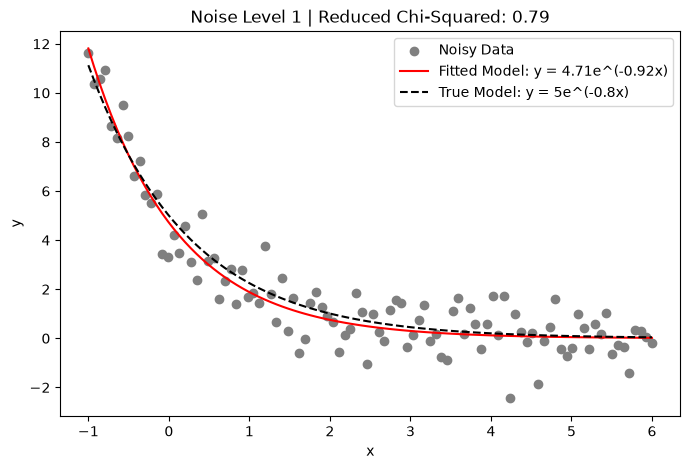

In [11]:
def model(x, A, k):
    return A * np.exp(-k * x)

x = df["x"]
y_noise_1 = df["y_noise_1"]

p0 = [1, 1]
popt, pcov = curve_fit(model, x, y_noise_1, p0=p0)
A_fit, k_fit = popt

print(f"Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x)")

residuals = y_noise_1 - model(x, A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(x) - len(popt)
chi2_reduced = chi2 / dof

plt.figure(figsize=(8, 5))
plt.scatter(x, y_noise_1, color="gray", label="Noisy Data")
plt.plot(x, model(x, A_fit, k_fit), color="red", label=f"Fitted Model: y = {A_fit:.2f}e^(-{k_fit:.2f}x)")
plt.plot(x, model(x, 5, 0.8), color="black", linestyle="--", label="True Model: y = 5e^(-0.8x)")
plt.title(f"Noise Level 1 | Reduced Chi-Squared: {chi2_reduced:.2f}")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

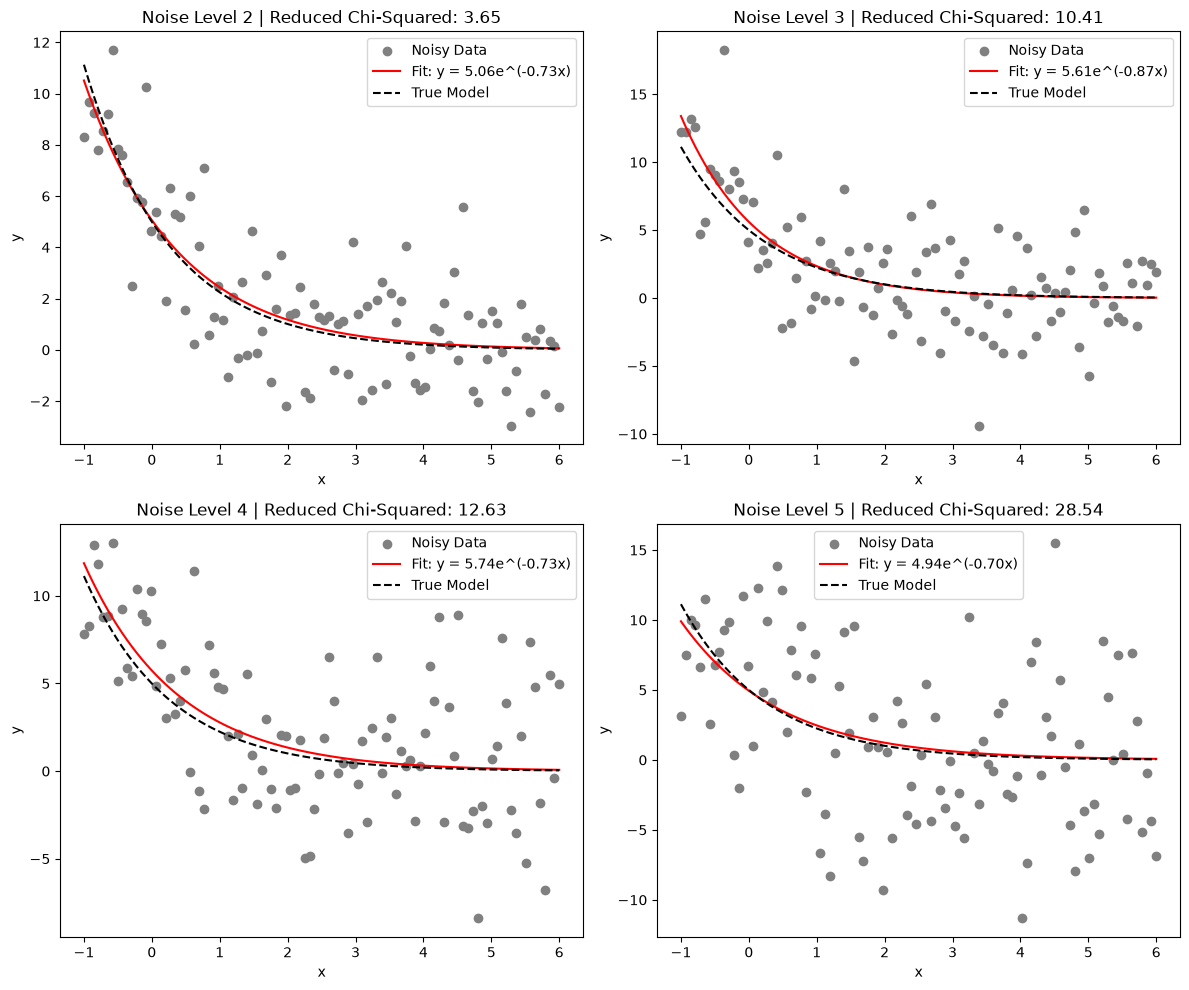

In [12]:
def fit_model(x, y):
    popt, _ = curve_fit(model, x, y, p0=[1, 1])
    A_f, k_f = popt
    residuals = y - model(x, A_f, k_f)
    chi2 = np.sum(residuals**2)
    dof = len(x) - len(popt)
    r_chi2 = chi2 / dof
    return A_f, k_f, r_chi2

# Store results starting with Noise Level 1
results = [
    {"Noise level": 1, "A fit": A_fit, "k fit": k_fit, "Reduced chi-squared": chi2_reduced}
]

noise_cols = ["y_noise_2", "y_noise_3", "y_noise_4", "y_noise_5"]
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, (ax, col) in enumerate(zip(axes, noise_cols), start=2):
    y_curr = df[col]
    A_f, k_f, r_chi2 = fit_model(x, y_curr)
    
    results.append({
        "Noise level": idx,
        "A fit": A_f,
        "k fit": k_f,
        "Reduced chi-squared": r_chi2
    })
    
    ax.scatter(x, y_curr, color="gray", label="Noisy Data")
    ax.plot(x, model(x, A_f, k_f), color="red", label=f"Fit: y = {A_f:.2f}e^(-{k_f:.2f}x)")
    ax.plot(x, model(x, 5, 0.8), color="black", linestyle="--", label="True Model")
    ax.set_title(f"Noise Level {idx} | Reduced Chi-Squared: {r_chi2:.2f}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend()

plt.tight_layout()
plt.show()

In [13]:
#What happens to the red and black dotted lines as you increase the noise level? Why?
    #The red line moves farther away from the black dotted line. Higher noise increases random scatter around the underlying curve, pulling the least squares fit away.

#What happens to the reduced chi-squared as you increase the noise level? Why?
    #The reduced chi squared value increases as the noise level increases because the vertical residuals grow larger when data points deviate farther from the curve.


In [14]:
results_df = pd.DataFrame(results)
print(results_df)
results_df.to_csv("noisy_parameters.csv", index=False)

   Noise level     A fit     k fit  Reduced chi-squared
0            1  4.714814  0.918308             0.790673
1            2  5.063889  0.730396             3.649382
2            3  5.609396  0.870372            10.410207
3            4  5.738727  0.725965            12.626832
4            5  4.943458  0.695012            28.538124
